# Load Data Into Dict

In [8]:
import src.read_write as read_write
import src.utils as utils
from pathlib import Path

dir_all_distortion_metrics = Path("data/all_distortion_metrics")

list_position = ["position1", "position2", "position3"]

list_techniques = ["IFFT", "CPROne", "CPRIter", "IDC", "IROC"]

list_orders = ["Order02", "Order04", "Order08", "Order12"]


# ============================================================
# Load all images
# ============================================================

images = {}

for technique in list_techniques:

    images[technique] = {}

    for position in list_position:

        # ====================================================
        # IFFT and IDC: no SSH order
        # ====================================================
        if technique in ["IFFT", "IDC"]:

            pattern = f"{position}*ROreg_ES000*{technique}_OrderNA"

            matching_dirs = list(dir_all_distortion_metrics.glob(pattern))

            if len(matching_dirs) == 0:
                print(f"No directory found for {technique}, {position}")
                continue

            if len(matching_dirs) > 1:
                print(f"Multiple directories found for {technique}, {position}:")
                for d in matching_dirs:
                    print("   ", d)

            directory = matching_dirs[0]

            file = directory / "phantom_2_ulf_distortion-magnitude.nii.gz"

            _, img = read_write.load_nii(file)

            images[technique][position] = img

            print(f"Loaded: {file}")

        # ====================================================
        # CPROne, CPRIter, IROC: load all SSH orders
        # ====================================================
        else:

            images[technique][position] = {}

            for order in list_orders:

                pattern = f"{position}*ROreg_ES000*{technique}_{order}"

                matching_dirs = list(dir_all_distortion_metrics.glob(pattern))

                if len(matching_dirs) == 0:
                    print(f"No directory found for {technique}, {position}, {order}")
                    continue

                if len(matching_dirs) > 1:
                    print(
                        f"Multiple directories found for "
                        f"{technique}, {position}, {order}:"
                    )
                    for d in matching_dirs:
                        print("   ", d)

                directory = matching_dirs[0]

                file = directory / "phantom_2_ulf_distortion-magnitude.nii.gz"

                _, img = read_write.load_nii(file)

                images[technique][position][order] = img

                print(f"Loaded: {file}")

Loaded: data/all_distortion_metrics/position1_ROreg_ES000_IFFT_OrderNA/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position2_ROreg_ES000_IFFT_OrderNA/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position3_ROreg_ES000_IFFT_OrderNA/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position1_ROreg_ES000_CPROne_Order02/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position1_ROreg_ES000_CPROne_Order04/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position1_ROreg_ES000_CPROne_Order08/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position1_ROreg_ES000_CPROne_Order12/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position2_ROreg_ES000_CPROne_Order02/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position2_ROreg_ES000_CPROne_Order04/phantom_2_ulf

# Plot Distortion Per Slice (Relative to Isocenter)

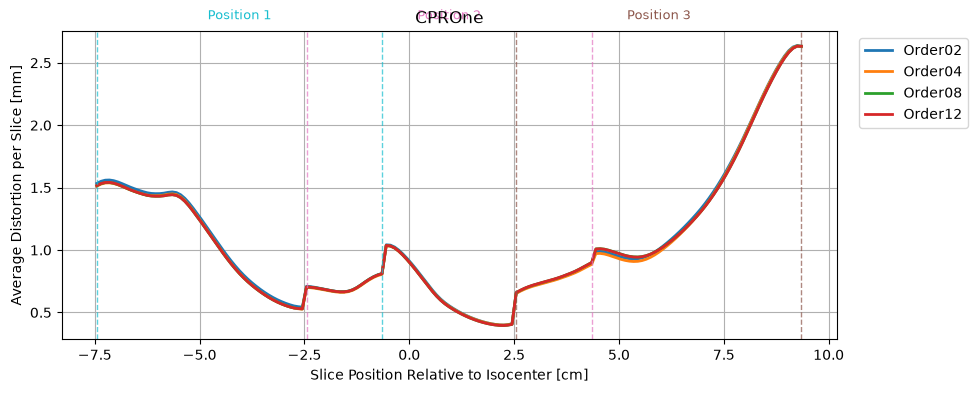

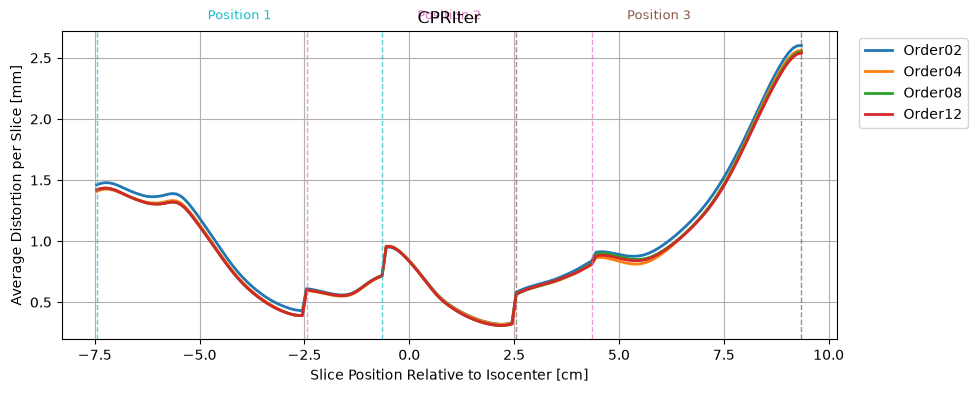

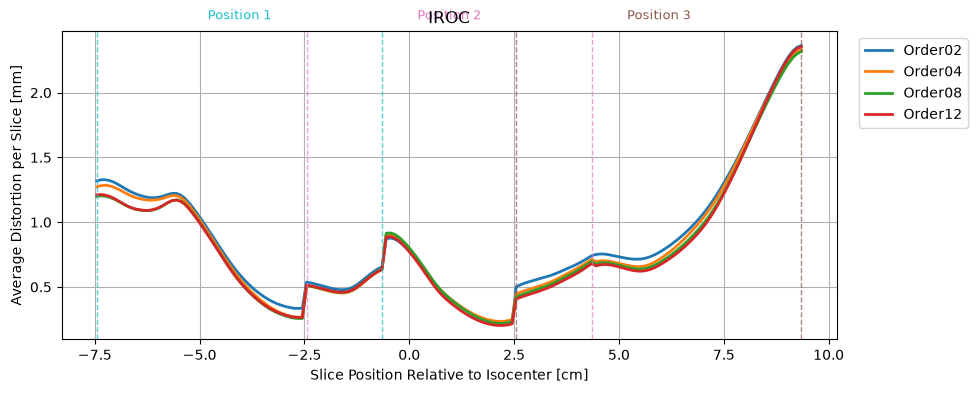

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.transforms import blended_transform_factory


# ============================================================
# Settings
# ============================================================

voxel_size_mm = 1.0
voxel_size_cm = voxel_size_mm / 10

start = 94
end = 163

distance_in_voxels = end - start
distance_in_cm = distance_in_voxels * voxel_size_cm

isocenter = distance_in_cm / 2 - 1
distance_phantom_positions = 5

list_orders = ["Order02", "Order04", "Order08", "Order12"]
plot_techniques = ["CPROne", "CPRIter", "IROC"]


# ============================================================
# Masking
# ============================================================

#_, mask = read_write.load_nii("data/ground_truth/Full_Phantom_Mask.nii.gz")


radius_in_vox = 83          # Ground Truth Phantom Radius   = 83 mm
height_in_vox = 74          # Ground Truth Phantom Height   = 74 mm
center = (115, 115, 128)    # Center was Determined from Ground Truth Phantom Images

mask = utils.create_cylinder_mask(volume_shape=(230, 230, 230),
                              cylinder_center=center,
                              height_in_vox=height_in_vox,
                              radius_in_vox=radius_in_vox).astype(bool)

# ============================================================
# Position ranges
# ============================================================

n_slices = end - start

position_ranges = {

    "position1": (
        -isocenter - distance_phantom_positions,

        (n_slices - 1) * voxel_size_cm
        - isocenter
        - distance_phantom_positions,
    ),

    "position2": (
        -isocenter,

        (n_slices - 1) * voxel_size_cm
        - isocenter,
    ),

    "position3": (
        -isocenter + distance_phantom_positions,

        (n_slices - 1) * voxel_size_cm
        - isocenter
        + distance_phantom_positions,
    ),
}


position_colors = {
    "position1": "tab:cyan",
    "position2": "tab:pink",
    "position3": "tab:brown"
}

position_names = {
    "position1": "Position 1",
    "position2": "Position 2",
    "position3": "Position 3"
}


# ============================================================
# Calculate and plot one figure per technique
# ============================================================

for technique in plot_techniques:

    data = {}

    # --------------------------------------------------------
    # Calculate data for each SSH order
    # --------------------------------------------------------

    for order in list_orders:

        x_values_all = []
        y_values_all = []

        for position in list_position:

            if position not in images[technique]:
                continue

            if order not in images[technique][position]:
                continue

            img = images[technique][position][order]

            # Apply mask
            img = img * mask

            # Crop
            img = img[:, :, start:end]

            # Position-dependent x coordinate
            if position == "position1":

                x_values = (
                    np.arange(img.shape[2]) * voxel_size_cm
                    - isocenter
                    - distance_phantom_positions
                )

            elif position == "position2":

                x_values = (
                    np.arange(img.shape[2]) * voxel_size_cm
                    - isocenter
                )

            elif position == "position3":

                x_values = (
                    np.arange(img.shape[2]) * voxel_size_cm
                    - isocenter
                    + distance_phantom_positions
                )

            # Average magnitude over x/y dimensions
            slice_values = np.average(
                np.abs(img),
                axis=(0, 1)
            )

            # Reverse slice order
            slice_values = slice_values[::-1]

            x_values_all.append(x_values)
            y_values_all.append(slice_values)

        if len(x_values_all) == 0:
            continue

        # Combine positions
        x_all = np.concatenate(x_values_all)
        y_all = np.concatenate(y_values_all)

        # Avoid floating-point mismatches
        x_all = np.round(x_all, decimals=6)

        x_combined = np.unique(x_all)

        y_combined = np.array([
            np.mean(y_all[x_all == x])
            for x in x_combined
        ])

        data[order] = {
            "x": x_combined,
            "y": y_combined
        }


    # ========================================================
    # Plot
    # ========================================================
    technique_colors = {
    "IFFT": "blue",
    "CPROne": "orange",
    "CPRIter": "green",
    "IDC": "purple",
    "IROC": "red",
}

    fig, ax = plt.subplots(figsize=(10, 4))

    for order in list_orders:

        if order not in data:
            continue

        ax.plot(
            data[order]["x"],
            data[order]["y"],
            linewidth=2,
            label=order
        )


    # ========================================================
    # Mark position boundaries
    # ========================================================

    for position, (x_start, x_end) in position_ranges.items():

        ax.axvline(
            x_start,
            color=position_colors[position],
            linestyle="--",
            linewidth=1,
            alpha=0.7
        )

        ax.axvline(
            x_end,
            color=position_colors[position],
            linestyle="--",
            linewidth=1,
            alpha=0.7
        )


    # ========================================================
    # Position labels
    # ========================================================

    trans = blended_transform_factory(
        ax.transData,
        ax.transAxes
    )

    for position, (x_start, x_end) in position_ranges.items():

        ax.text(
            (x_start + x_end) / 2,
            1.03,
            position_names[position],
            ha="center",
            va="bottom",
            fontsize=9,
            color=position_colors[position],
            transform=trans,
            clip_on=False
        )


    # ========================================================
    # Formatting
    # ========================================================

    ax.set_xlabel("Slice Position Relative to Isocenter [cm]")
    ax.set_ylabel("Average Distortion per Slice [mm]")

    ax.set_title(technique)

    ax.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    ax.grid()

    plt.show()

# Read in Data Per position in pd

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ========================================================
# Settings
# ========================================================

plot_techniques = ["CPROne", "CPRIter", "IROC"]
list_orders = ["Order02", "Order04", "Order08", "Order12"]

# ========================================================
# Calculate mean distortion per position
# ========================================================

results = []

mask_bool = mask.astype(bool)

for technique in plot_techniques:

    for position in list_position:

        row = {
            "Technique": technique,
            "Position": position
        }

        for order in list_orders:

            if position not in images[technique]:
                continue

            if order not in images[technique][position]:
                continue

            img_full = images[technique][position][order]

            # ========================================================
            # Average only over masked voxels
            # ========================================================

            masked_values = np.abs(img_full)[mask_bool]

            row[order] = round(np.mean(masked_values), 2)

        results.append(row)


# ========================================================
# Create DataFrame
# ========================================================

df_distortion = pd.DataFrame(results)


# ========================================================
# Calculate average across the 3 positions
# ========================================================

df_average = (
    df_distortion
    .groupby("Technique")[list_orders]
    .mean()
    .round(2)
)

df_average["Position"] = "Average"

df_average = (
    df_average
    .reset_index()
    [["Technique", "Position"] + list_orders]
)


# ========================================================
# Combine positions + average
# ========================================================

df_distortion = pd.concat(
    [df_distortion, df_average],
    ignore_index=True
)


# ========================================================
# Display
# ========================================================

df_distortion

,Technique,Position,Order02,Order04,Order08,Order12
0,CPROne,position1,2.38,2.34,2.34,2.35
1,CPROne,position2,1.71,1.70,1.70,1.70
2,CPROne,position3,3.43,3.40,3.43,3.43
3,CPRIter,position1,2.15,2.05,2.05,2.05
4,CPRIter,position2,1.53,1.52,1.51,1.51
5,CPRIter,position3,3.25,3.14,3.16,3.15
6,IROC,position1,1.86,1.74,1.67,1.68
7,IROC,position2,1.33,1.38,1.38,1.33
8,IROC,position3,2.83,2.68,2.62,2.60
9,CPRIter,Average,2.31,2.24,2.24,2.24


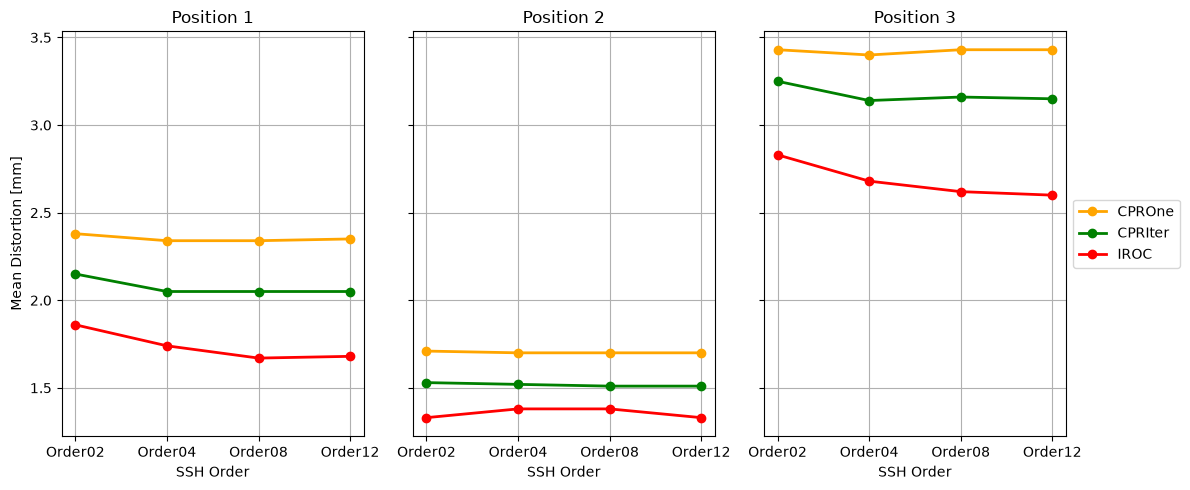

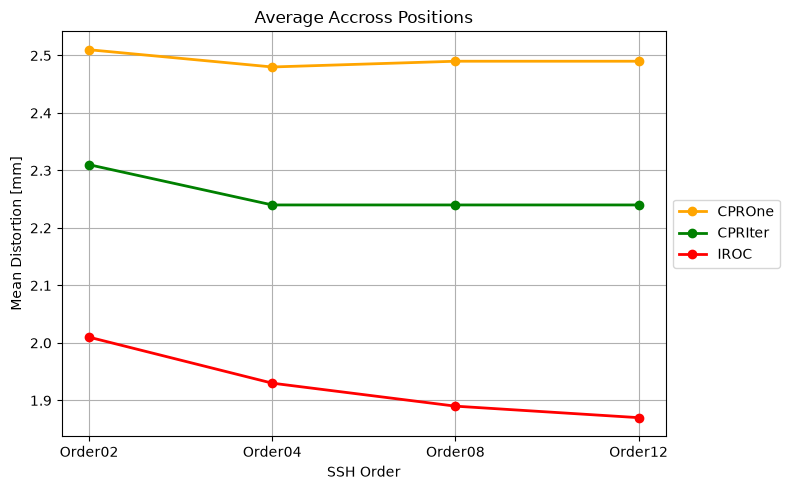

In [11]:
# ========================================================
# Plot Position 1, Position 2 and Position 3
# ========================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(12, 5),
    sharey=True
)

x = np.arange(len(list_orders))

technique_colors = {
    "CPROne": "orange",
    "CPRIter": "green",
    "IROC": "red",
}

positions_to_plot = [
    "position1",
    "position2",
    "position3"
]

position_titles = {
    "position1": "Position 1",
    "position2": "Position 2",
    "position3": "Position 3"
}


for ax, position in zip(axes, positions_to_plot):

    for technique in plot_techniques:

        row = df_distortion[
            (df_distortion["Technique"] == technique) &
            (df_distortion["Position"] == position)
        ]

        y = [
            row[order].iloc[0]
            for order in list_orders
        ]

        ax.plot(
            x,
            y,
            marker="o",
            linewidth=2,
            color=technique_colors[technique],
            label=technique
        )

    # Formatting
    ax.set_title(position_titles[position])

    ax.set_xticks(x)
    ax.set_xticklabels(list_orders)

    ax.set_xlabel("SSH Order")

    ax.grid()


# Shared Y-axis
axes[0].set_ylabel("Mean Distortion [mm]")


# Legend
axes[-1].legend(
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.tight_layout()
plt.show()


# ========================================================
# Plot Average across Position 1, 2 and 3
# ========================================================

fig, ax = plt.subplots(figsize=(8, 5))

for technique in plot_techniques:

    row = df_distortion[
        (df_distortion["Technique"] == technique) &
        (df_distortion["Position"] == "Average")
    ]

    y = [
        row[order].iloc[0]
        for order in list_orders
    ]

    ax.plot(
        x,
        y,
        marker="o",
        linewidth=2,
        color=technique_colors[technique],
        label=technique
    )


# Formatting
ax.set_title("Average Accross Positions")
ax.set_xticks(x)
ax.set_xticklabels(list_orders)

ax.set_xlabel("SSH Order")
ax.set_ylabel("Mean Distortion [mm]")

ax.grid()

ax.legend(
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.tight_layout()
plt.show()